In [8]:
# 第一题代码
# import pandas 
import pandas as pd
# import numpy
import numpy as np
# import matplotlib
from matplotlib import pyplot as plt
# make plots appear and be stored within the notebook
%matplotlib inline

In [9]:
# 引入tsv文档
Sig_Eqs = pd.read_csv("earthquakes-2026-10-27_15-13-38_+0800.tsv",sep="\t")
# 读前5行 看看文件有什么内容
Sig_Eqs.head()

,Search Parameters,Id,Year,Mo,Dy,Hr,Mn,Sec,Tsu,Vol,...,Total Missing,Total Missing Description,Total Injuries,Total Injuries Description,Total Damage ($Mil),Total Damage Description,Total Houses Destroyed,Total Houses Destroyed Description,Total Houses Damaged,Total Houses Damaged Description
0,[],NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,1.0,-2150.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,2.0,-2000.0,NaN,NaN,NaN,NaN,NaN,1.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,3.0,-2000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,1.0,NaN,1.0,NaN,NaN
4,NaN,5877.0,-1610.0,NaN,NaN,NaN,NaN,NaN,3.0,1351.0,...,NaN,NaN,NaN,NaN,NaN,3.0,NaN,NaN,NaN,NaN


In [34]:
# 1.1
# 计算自公元前2150年以来每个国家的死亡人数
# 先把国家分组
DP = Sig_Eqs.groupby("Country") ["Deaths"].sum()
# 打印死亡最多的20个国家及死亡人数
maxDP = DP.sort_values(ascending=False).head(20)
maxDP

Country
CHINA           2139225.0
TURKEY          1199720.0
IRAN            1014438.0
ITALY            492236.0
HAITI            323484.0
AZERBAIJAN       319251.0
SYRIA            289826.0
JAPAN            242516.0
ARMENIA          177890.0
PAKISTAN         145085.0
IRAQ             136200.0
ECUADOR          135496.0
TURKMENISTAN     117412.0
PERU             102309.0
ISRAEL            93388.0
PORTUGAL          83572.0
GREECE            81162.0
CHILE             64277.0
INDIA             63507.0
TAIWAN            57154.0
Name: Deaths, dtype: float64

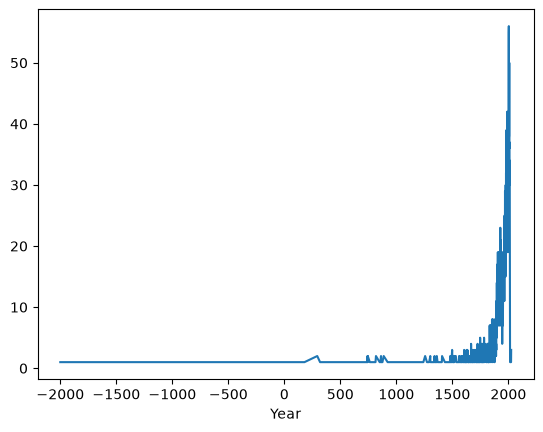

In [33]:
# 1.2 计算MS
# 筛选等级大于3的地震
EQ = Sig_Eqs[Sig_Eqs["Ms"] > 3.0]
# 把年份分组
year1 = EQ.groupby("Year").size()
year1 = year1.sort_index()
# 绘制时间序列图
year1.plot()
plt.show()
# 趋势
# 随时间的增长，震级的次数越来越多
# 原因可能是：时代在进步，技术发展了，越来越多的地震现象被观察或观测。



In [54]:
# 1.3 定义函数
def CountEq_LargestEq(country):
    # 统计各个国家的地震次数
    data = Sig_Eqs[Sig_Eqs["Country"] == country]

    count = len(data)

    data = data.dropna(subset=["Mag"])
    
    if len(data) == 0:
        return count, "Unknown", "Unknown"
    # 按照震级大小排序
    largest = data.sort_values("Mag", ascending=False).iloc[0]

    year = str(int(largest["Year"]))

    date = year

    if pd.notna(largest["Mo"]):
        date += "-" + str(int(largest["Mo"])).zfill(2)

        if pd.notna(largest["Dy"]):
            date += "-" + str(int(largest["Dy"])).zfill(2)
    # 提取发生地点
    location = largest["Location Name"]
    # 返回值
    return count, date, location

In [55]:
CountEq_LargestEq("CHINA")

(627, '1668-07-25', 'CHINA:  SHANDONG PROVINCE')

In [56]:
CountEq_LargestEq("JAPAN")

(429, '2011-03-11', 'JAPAN:  HONSHU')

C:\Users\谢豪杰\AppData\Local\Temp\ipykernel_27772\2623255995.py:6: DtypeWarning: Columns (0: CALL_SIGN, 1: AA3, 2: AG1, 3: AJ1, 4: AW1, 5: AZ1, 6: CALL_SIGN.1, 7: GA5, 8: GE1, 9: HL1, 10: IA2, 11: KA2, 12: ME1, 13: MW3, 14: OA1, 15: OD1, 16: OD2, 17: SA1, 18: UA1, 19: UG1) have mixed types. Specify dtype option on import or set low_memory=False.
  bw = pd.read_csv("Baoan_Weather_1998_2022.csv")


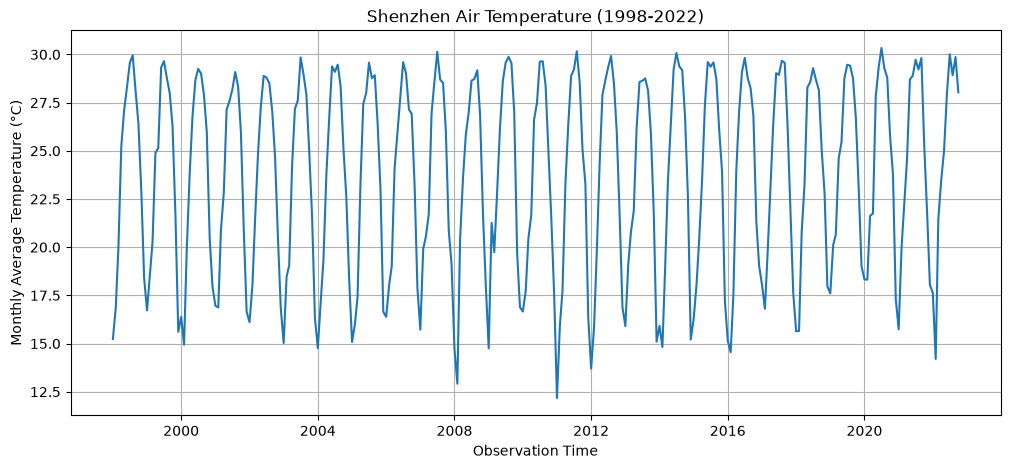

In [69]:
# 第二题代码
# 
import pandas as pd
import matplotlib.pyplot as plt

bw = pd.read_csv("Baoan_Weather_1998_2022.csv")

# 把TMP分为温度数值和质量检查代码
bw["Temp"] = bw["TMP"].str.split(",").str[0]
bw["Code"] = bw["TMP"].str.split(",").str[1]

# 把温度字符串转换为数字
bw["Temp"] = pd.to_numeric(bw["Temp"], errors="coerce")
bw = bw[bw["Temp"] != 9999]
bw = bw[bw["Code"].isin(["1", "5"])]

# 实际温度等于原始温度除以10
bw["Temperature"] = bw["Temp"] / 10
bw["DATE"] = pd.to_datetime(bw["DATE"])

# 求不同月份温度平均值
bw["Month"] = bw["DATE"].dt.to_period("M")
monthly = bw.groupby("Month")["Temperature"].mean()

bw.head()

x = monthly.index.to_timestamp()
y = monthly.values


plt.figure(figsize=(12, 5))
plt.plot(x, y)

# 设置坐标轴名称
plt.xlabel("Observation Time")
plt.ylabel("Monthly Average Temperature (°C)")
plt.title("Shenzhen Air Temperature (1998-2022)")
plt.grid(True)
plt.show()

C:\Users\谢豪杰\AppData\Local\Temp\ipykernel_27772\3497084635.py:9: DtypeWarning: Columns (0: NAME) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('ibtracs.ALL.list.v04r00.csv',


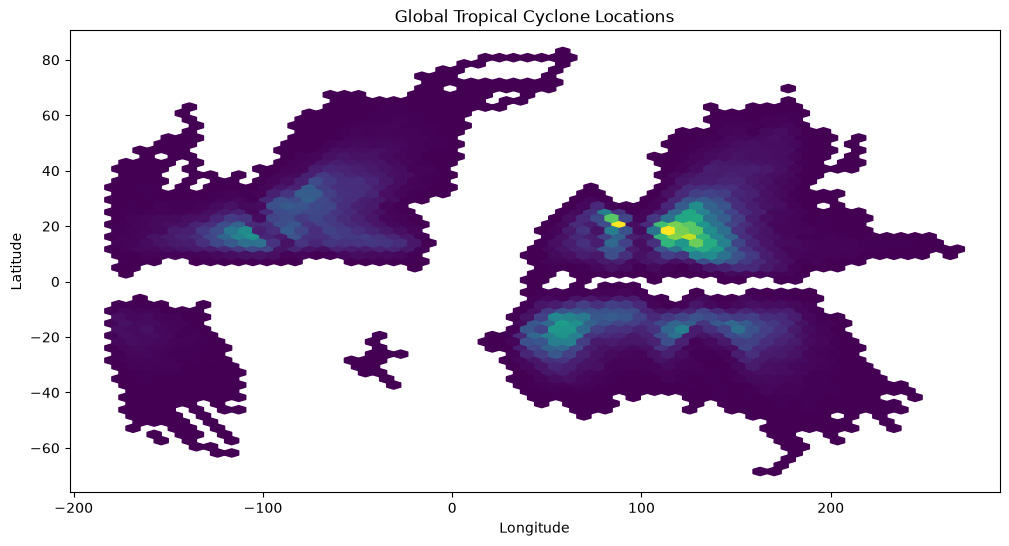

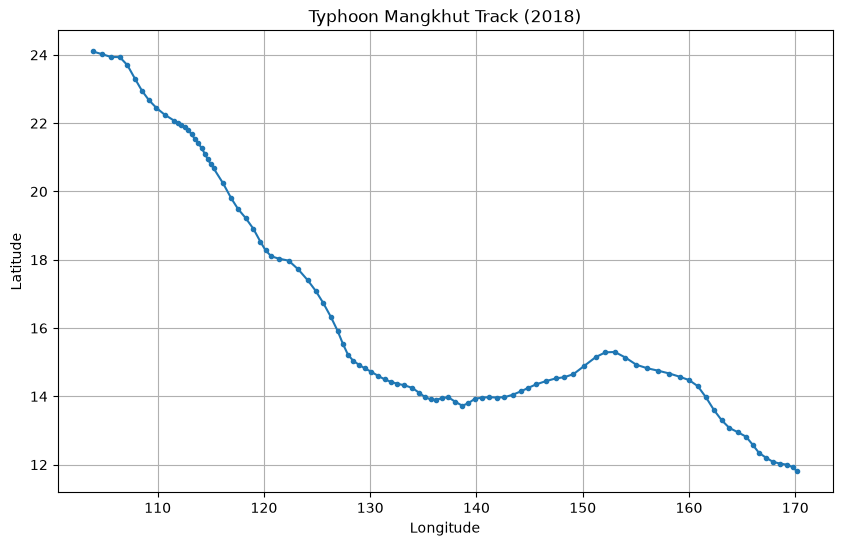

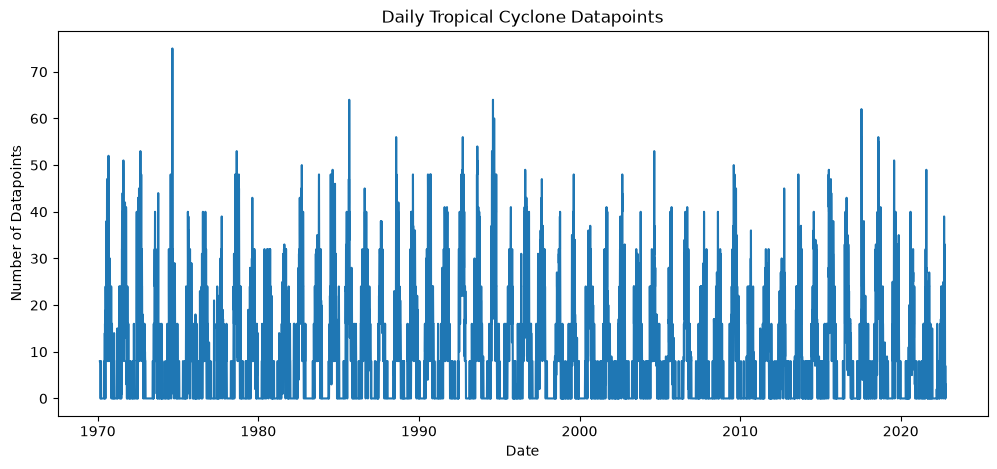

In [77]:
# 第三题代码
# import pandas 
import pandas as pd
# import numpy
import numpy as np
# import matplotlib
from matplotlib import pyplot as plt

df = pd.read_csv('ibtracs.ALL.list.v04r00.csv',
    usecols=range(17),
    skiprows=[1, 2],
    parse_dates=['ISO_TIME'],
    na_values=['NOT_NAMED', 'NAME']
)

# 将风速转换为数字
df["WMO_WIND"] = pd.to_numeric(
    df["WMO_WIND"],
    errors="coerce"
)

# 确保经纬度是数字
df["LAT"] = pd.to_numeric(df["LAT"], errors="coerce")
df["LON"] = pd.to_numeric(df["LON"], errors="coerce")

# 确保时间为日期时间类型
df["ISO_TIME"] = pd.to_datetime(df["ISO_TIME"], errors="coerce")

# 查看前5行
df.head()

# 3.1题 
SW = df.groupby("SID").agg({
    "NAME": "first",
    "WMO_WIND": "max"
})
NAME = SW.sort_values("WMO_WIND",ascending=False).head(10)

# 3.2
MAX_WIND = SW.sort_values("WMO_WIND",ascending=False).head(20)

# 3.3
# 海域分组
basin = df.groupby("BASIN").size()
basin = basin.sort_values(ascending=False)

# 3.4
# 先删除没有经纬度的记录
location = df.dropna(subset=["LAT", "LON"])

plt.figure(figsize=(12, 6))

# 绘制六边形密度图
plt.hexbin(
    location["LON"],
    location["LAT"],
    gridsize=60,
    mincnt=1
)

# 设置坐标轴
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Global Tropical Cyclone Locations")

plt.show()

# 3.5
# 筛选2018年的山竹台风
mangkhut = df[
    (df["NAME"] == "MANGKHUT") &
    (df["SEASON"] == 2018)
]

# 只保留主要轨迹
mangkhut = mangkhut[
    mangkhut["TRACK_TYPE"].str.lower() == "main"
]

# 按时间排序
mangkhut = mangkhut.sort_values("ISO_TIME")

# 设置X轴和Y轴
x = mangkhut["LON"]
y = mangkhut["LAT"]

# 绘制轨迹
plt.figure(figsize=(10, 6))
plt.plot(x, y, marker=".")

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Typhoon Mangkhut Track (2018)")
plt.grid(True)
plt.show()

# 3.6
# 1970年以后的气旋季节
df2 = df[df["SEASON"] >= 1970]

# WP和EP两个海域
df2 = df2[df2["BASIN"].isin(["WP", "EP"])].copy()
df2.head()

# 3.7
# 筛选没有观测时间的记录
df2 = df2.dropna(subset=["ISO_TIME"])

# 每天分组
daily = df2.set_index("ISO_TIME").resample("D").size()

# 绘图
plt.figure(figsize=(12, 5))
plt.plot(daily.index, daily.values)

plt.xlabel("Date")
plt.ylabel("Number of Datapoints")
plt.title("Daily Tropical Cyclone Datapoints")

plt.show()

# 3.8
# 提取每个日期是一年中的第几天
day_number = daily.index.dayofyear
# 按一年中的日期序号分组，计算多年平均
climatology = daily.groupby(day_number).mean()

# 3.9 计算每日距平

# 获取每一天在一年中的序号
normal = climatology.loc[day_number].values
# 计算每日距平
anomaly = daily - normal

# 3.10 计算年度累计距平
# 按年份汇总每日距平
annual = anomaly.resample("YE").sum()


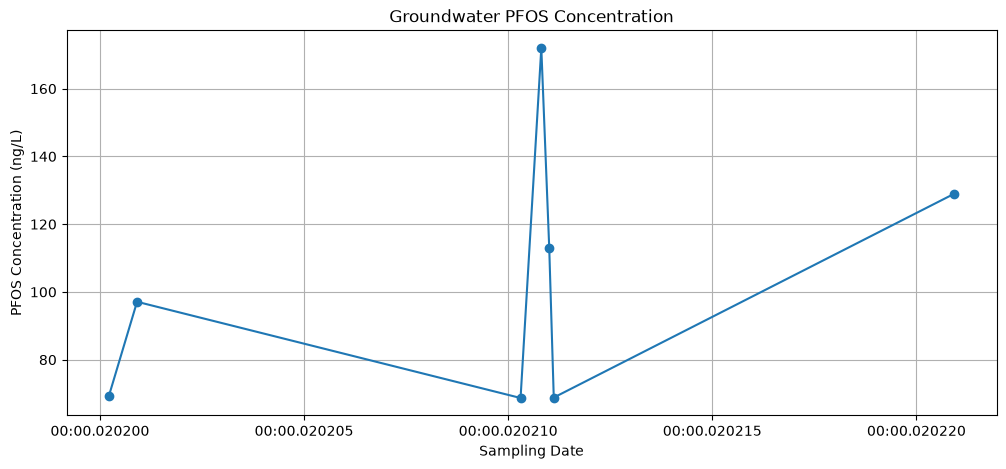

样本数量： 7
平均值： 102.56142857142856
中位数： 97.1
最大值： 172.0
最小值： 68.7


In [90]:
# 第四题
# import pandas 
import pandas as pd
# import numpy
import numpy as np
# import matplotlib
from matplotlib import pyplot as plt

# 4.1
df = pd.read_csv("CapeCodPFAS_2019_2024_ver_2_0.csv")

# 去掉空白数据
df["Sample_Type"] = df["Sample_Type"].str.strip()

# 筛选地下水和指定监测点
data = df[
    (df["Sample_Type"] == "GW") &
    (df["SiteID_DON"] == "413735070320730")
].copy()

# 将日期转换为日期时间类型
data["Date"] = pd.to_datetime(
    data["Date_yyyymmdd"],
    errors="coerce"
)

# 将PFOS浓度转换为数字
data["PFOS"] = pd.to_numeric(
    data["PFOS_val"],
    errors="coerce"
)

# 删除日期或浓度缺失的记录
data = data.dropna(subset=["Date", "PFOS"])
(data[["Date", "PFOS"]])

# 4.2
# 指定横纵坐标
x = data["Date"]
y = data["PFOS"]

plt.figure(figsize=(12, 5))
plt.plot(x, y, marker="o")
plt.xlabel("Sampling Date")
plt.ylabel("PFOS Concentration (ng/L)")
plt.title("Groundwater PFOS Concentration")
plt.grid(True)
plt.show()

# 4.3
# 有效样本数量
Count = data["PFOS"].count()
# 平均值
Mean = data["PFOS"].mean()
Mean
# 中位数
Median = data["PFOS"].median()
# 最大值
Maximum = data["PFOS"].max()
# 最小值
Minimum = data["PFOS"].min()

print("样本数量：", Count)
print("平均值：", Mean)
print("中位数：", Median)
print("最大值：", Maximum)
print("最小值：", Minimum)